# ecDNA tests

## Imports and configuration

In [1]:
# Import DNAscape
from dnascape import *

## Data management

In [2]:
import numpy as np
from scipy.optimize import curve_fit
import pybigtools


def sigmoid(x, k, x0):
    return 1.0 / (1.0 + np.exp(-k * (x - x0)))


def compute_timing_curve(chrom, start, end, cell_line="DM", resolution=10_000):
    bins = ["S1", "S2", "S3", "S4", "S5"]
    x_bins = np.arange(1, 6, dtype=float)

    bw_files = [
        pybigtools.open(f"data/repliseq/{cell_line}_{b}_{resolution}.bw")
        for b in bins
    ]

    positions = np.arange(start, end, resolution)
    rt_values = []

    try:
        for pos in positions:
            signals = []

            for bw in bw_files:
                vals = bw.values(chrom, pos, pos + resolution)

                if vals is None:
                    signals.append(np.nan)
                else:
                    vals = np.array(
                        [np.nan if v is None else float(v) for v in vals],
                        dtype=float
                    )
                    signals.append(np.nanmean(vals) if vals.size > 0 else np.nan)

            signals = np.array(signals, dtype=float)

            if np.any(np.isnan(signals)) or np.sum(signals) == 0:
                rt_values.append(np.nan)
                continue

            norm_signals = signals / np.sum(signals)
            cumulative = np.cumsum(norm_signals)

            try:
                popt, _ = curve_fit(
                    sigmoid,
                    x_bins,
                    cumulative,
                    p0=[2, 3],
                    bounds=([0.1, 1], [10, 5])
                )
                _, x0 = popt
                rt_values.append(x0)
            except RuntimeError:
                rt_values.append(np.nan)

    finally:
        for bw in bw_files:
            bw.close()

    return positions, np.array(rt_values)

In [3]:
positions, timing_curve = compute_timing_curve(
    chrom="chr8",
    start=124_000_000,
    end=131_000_000,
    cell_line="DM",
    resolution=10_000
)

In [4]:
def refinef(x, resolution_factor=1, mode="smooth"):
    x = np.asarray(x, dtype=float)
    if len(x) == 0:
        return x
    if resolution_factor <= 0:
        raise ValueError("resolution_factor must be positive")

    m = max(1, int(round(len(x) * resolution_factor)))
    u = np.clip(np.arange(m) / resolution_factor, 0, len(x) - 1)

    if mode == "smooth":
        return np.interp(u, np.arange(len(x)), x)
    if mode == "const":
        return x[np.clip(np.floor(u + 0.5).astype(int), 0, len(x) - 1)]
    raise ValueError("mode must be 'smooth' or 'const'")

def smoothf(data, window=50):
    data = np.asarray(data, float)
    n = len(data)
    win = min(window, n)
    kernel = np.ones(win, float)

    size = n + win - 1
    conv = irfft(rfft(data, size) * rfft(kernel, size), size)
    norm = irfft(rfft(np.ones(n), size) * rfft(kernel, size), size)

    start = win // 2
    conv = conv[start:start + n]
    norm = norm[start:start + n]

    return conv / norm

In [5]:
savetxt(timing_curve, stitle='replication_timing_ecDNA_1', outpath="replication_timing")

## Data polish

In [6]:
timedata_raw = loadtxt(stitle='replication_timing_ecDNA_1', outpath="replication_timing")

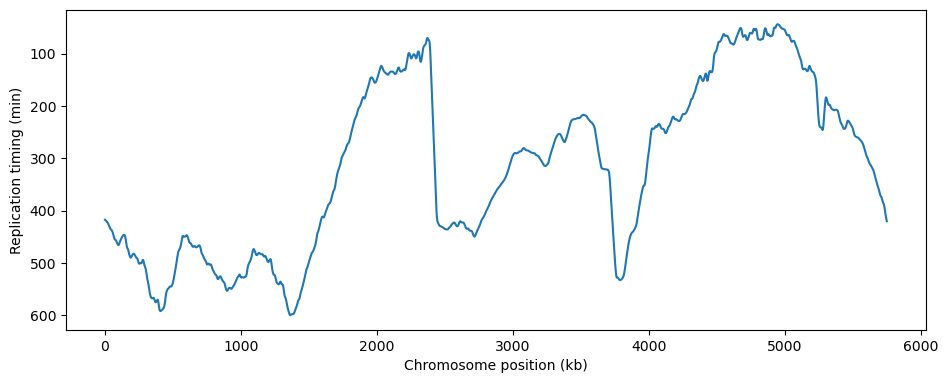

In [7]:
timedata = smoothf(refinef(timedata_raw, resolution_factor=10),window=50)
timedata = rescale(timedata, (600,30))[0:5750]
positions = refinef(positions, resolution_factor=10)[0:5750]
plotf(timedata, invyQ=True, xtitle='Chromosome position (kb)', ytitle='Replication timing (min)')

## Bound tests

In [ ]:
fork_speed = 1.4
periodicQ = True

frates = rfit('replication_timing', 'firing_rate',
              source=timedata, fork_speed=fork_speed, maxiter=10, fit_step=2, perQ=periodicQ)

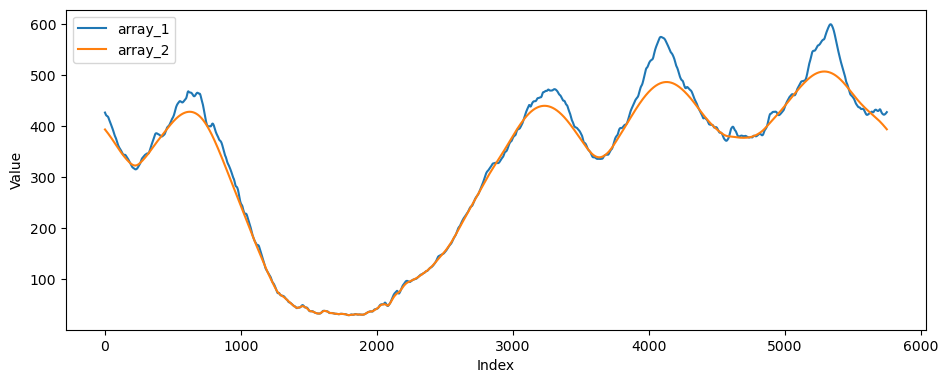

In [111]:
timepred = rfit('firing_rate', 'replication_timing', source=frates, perQ=periodicQ)
plotf(timedata, timepred)

In [124]:
simres = rsim(ori_rate=frates, fork_speed=fork_speed, sim_number=1000, perQ=True, time_statsQ=True,
    time_stats_xtQ=False, time_stats_densQ=None)
timesim = simres['replication_timing']
stimes = simres['s_phase_duration']
rep_times_per_sim = simres['rep_times_per_sim']

[1000/1000]  Elapsed: 00:01:46  ETA: 00:00:00

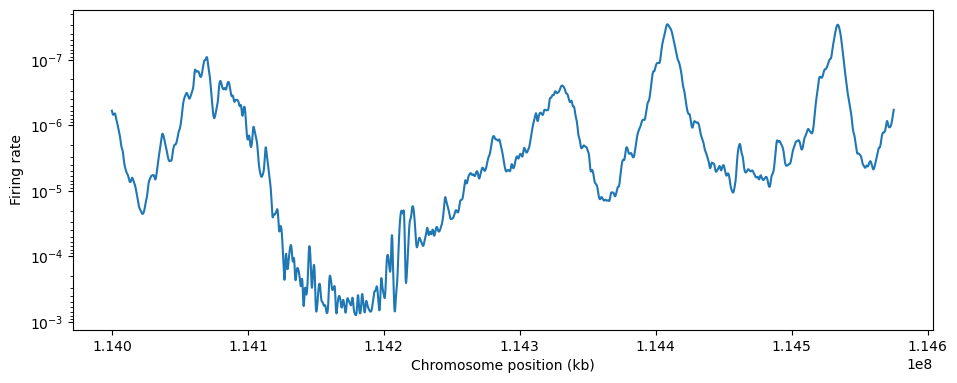

In [113]:
plotf(frates, logyQ=True, x_array=positions, invyQ=True, xtitle='Chromosome position (kb)', ytitle='Firing rate', saveQ=True)

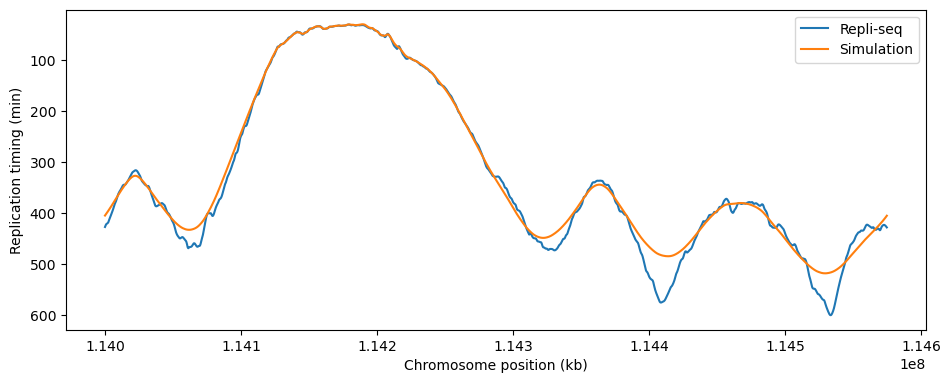

In [114]:
plotf(timedata, timesim, x_array=positions, invyQ=True, xtitle='Chromosome position (kb)', ytitle='Replication timing (min)', labels=['Repli-seq', 'Simulation'], saveQ=True)

In [87]:
import numpy as np
import matplotlib.pyplot as plt

def plot_replicated_fraction_map(rep_times_per_sim, dx=1.0, nt=300, cmap="viridis", ylims=None):
    tau = np.asarray(rep_times_per_sim, dtype=float)
    if tau.ndim != 2:
        raise ValueError("rep_times_per_sim must have shape (n_sims, n_pos)")

    n_sims, n_pos = tau.shape
    x = np.arange(n_pos) * dx

    tmin = np.nanmin(tau)
    tmax = np.nanmax(tau)
    t_grid = np.linspace(tmin, tmax, nt)

    # S[i, j] = fraction replicated at time t_grid[i] and position x[j]
    S = (tau[None, :, :] < t_grid[:, None, None]).mean(axis=1)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    im = ax.imshow(
        S,
        aspect="auto",
        origin="lower",
        extent=[x[0], x[-1], t_grid[0], t_grid[-1]],
        cmap=cmap,
        vmin=0.0,
        vmax=1.0,
    )

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("Replicated fraction")

    ax.set_xlabel("Position")
    ax.set_ylabel("Time")
    ax.set_title(r"Empirical replicated fraction $f(x,t)$")

    if ylims is not None:
        ax.set_ylim(*ylims)

    plt.tight_layout()
    return fig, ax, x, t_grid, S

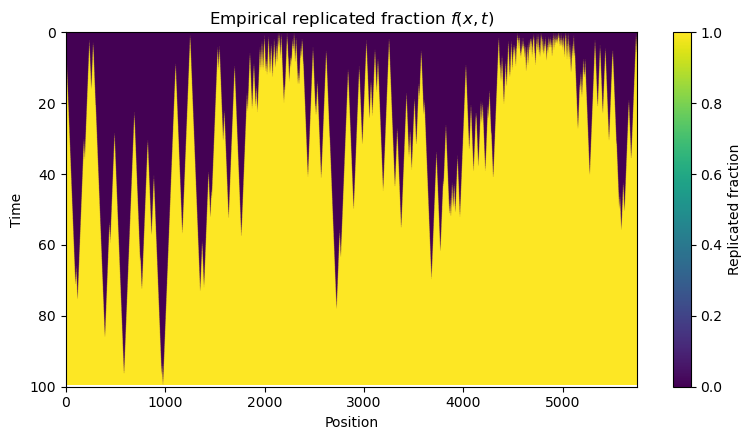

In [91]:
fig, ax, x, t_grid, S = plot_replicated_fraction_map(
    rep_times_per_sim[0:1],
    dx=1.0,
    nt=300,
    cmap="viridis",
    ylims=(100, 0)
)
plt.tight_layout()
#fig.savefig("figures/figure.pdf", bbox_inches="tight")
plt.show()

### Explicit completion-time bounds

Derived quantities
------------------
L         = 5750.0
dx        = 1.0
vmin      = 1.4
ell0_min  = 2.655288253293596
ell0_max  = 1092.5929200090086

Paper notation
--------------
a         = ell0_max = 1092.5929200090086
theta0    = ell0_min / ell0_max = 0.0024302630967732272
I0_min    = 0.0001463450911251757
c0        = I0_min * theta0 = 3.556570743554296e-07

Comparison
----------
E_theory   = 1676.6369536901022
E_empirical= 60.34979714622264


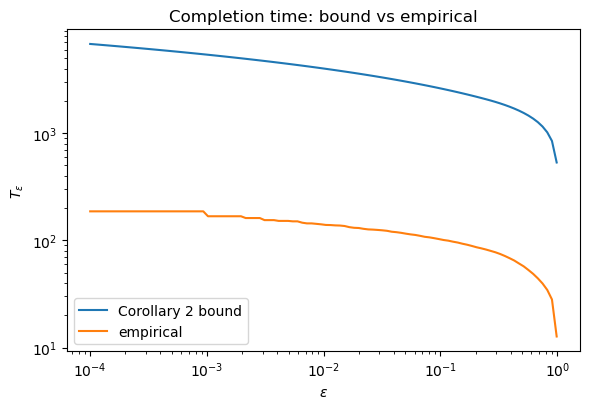

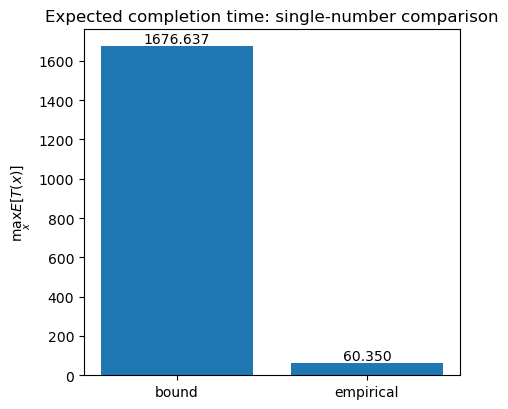

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from math import erf, sqrt, pi, exp


# ============================================================
# Helpers
# ============================================================

def _higher_quantiles(x, q):
    """
    For x with shape (n_sims, n_pos), return the upper q-quantiles
    along the simulation axis.
    """
    x = np.sort(np.asarray(x, dtype=float), axis=0)
    n = x.shape[0]
    q = np.asarray(q, dtype=float)
    k = np.clip(np.ceil(q * n).astype(int) - 1, 0, n - 1)
    return x[k]


def _circ_avg(I, start, length, prefix=None):
    """
    Circular average of I over an arc of given length, starting at index 'start'.
    Length may be non-integer.
    """
    I = np.asarray(I, dtype=float)
    n = len(I)
    L = float(n)

    if length <= 0:
        return 0.0
    if length >= L:
        return float(I.mean())

    if prefix is None:
        mass = np.concatenate([I, I])
        prefix = np.concatenate([[0.0], np.cumsum(mass)])

    q = int(np.floor(length))
    r = float(length - q)

    total = prefix[start + q] - prefix[start]
    if r > 0:
        total += r * I[(start + q) % n]

    return total / length


# ============================================================
# Paper quantities: Lambda_0, ell_0, theta_0, I0_min, a, c0
# ============================================================

def build_torus_quantities(frates, rep_times_per_sim, fork_speed=1.4):
    """
    Build the quantities appearing in the paper, specialised to the torus case.

    We use:
        timedata(x) = empirical mean replication time at position x
        Lambda0(x)  = I(x) * timedata(x)
        ell0(x)     = 1 / Lambda0(x)

    Then:
        a      = ell0,max
        theta0 = ell0,min / ell0,max
        I0_min = min_j average of I over an arc of length ell0(j), starting at j
        c0     = I0_min * theta0
    """
    global I, I0_min, c0
    
    I = np.asarray(frates, dtype=float)
    tau = np.asarray(rep_times_per_sim, dtype=float)

    if I.ndim != 1:
        raise ValueError("frates must be a 1D array")
    if tau.ndim != 2:
        raise ValueError("rep_times_per_sim must have shape (n_sims, n_pos)")
    if tau.shape[1] != len(I):
        raise ValueError("rep_times_per_sim.shape[1] must equal len(frates)")
    if np.any(I <= 0):
        raise ValueError("frates must be strictly positive")
    if np.any(tau <= 0):
        raise ValueError("replication times must be strictly positive")

    L = float(len(I))      # assuming 1 kb resolution
    dx = 1.0
    vmin = float(fork_speed)

    timedata = tau.mean(axis=0)

    Lambda0 = I * timedata
    ell0 = 1.0 / Lambda0

    ell0_min = float(ell0.min())
    ell0_max = float(ell0.max())

    a = ell0_max
    if not (0.0 < a < L):
        raise ValueError(f"Need 0 < a < L, got a={a}, L={L}")

    theta0 = ell0_min / ell0_max

    mass = np.concatenate([I, I])
    prefix = np.concatenate([[0.0], np.cumsum(mass)])
    I0_min = min(_circ_avg(I, j, ell0[j], prefix) for j in range(len(I)))

    c0 = float(I0_min * theta0)
    if c0 <= 0:
        raise ValueError("Computed c0 <= 0")

    return {
        "L": L,
        "dx": dx,
        "vmin": vmin,
        "I": I,
        "tau": tau,
        "timedata": timedata,
        "Lambda0": Lambda0,
        "ell0": ell0,
        "ell0_min": ell0_min,
        "ell0_max": ell0_max,
        "theta0": float(theta0),
        "I0_min": float(I0_min),
        "a": float(a),
        "c0": float(c0),
    }


# ============================================================
# Explicit bounds from the paper
# ============================================================

def bound_corollary2(eps, L, vmin, a, c0):
    """
    Corollary 2, torus case:
    explicit bound for T_eps.
    """
    eps = np.asarray(eps, dtype=float)
    if np.any((eps <= 0) | (eps >= 1)):
        raise ValueError("eps must lie strictly in (0, 1)")

    rhs = np.log(1.0 / eps)
    threshold = c0 * (L - a) ** 2 / (4.0 * vmin)

    T = np.empty_like(rhs)

    quad = rhs <= threshold
    lin = ~quad

    T[quad] = a / (2.0 * vmin) + np.sqrt(rhs[quad] / (c0 * vmin))
    T[lin] = (L + a) / (4.0 * vmin) + rhs[lin] / (c0 * (L - a))

    return T


def bound_proposition4(L, vmin, a, c0):
    """
    Proposition 4 style single-number bound used in the code:
    upper bound for max_x E[T(x)] in the torus setting.
    """
    z = (L - a) * sqrt(c0) / (2.0 * sqrt(vmin))
    return (
        a / (2.0 * vmin)
        + sqrt(pi) / (2.0 * sqrt(c0 * vmin)) * erf(z)
        + exp(-c0 * (L - a) ** 2 / (4.0 * vmin)) / (c0 * (L - a))
    )


# ============================================================
# Empirical quantities to compare against the bounds
# ============================================================

def empirical_completion_curve(tau, eps_grid):
    """
    Empirical counterpart of T_eps:
    for each epsilon, take the (1-epsilon)-quantile over simulations
    at each position, then maximise over position.
    """
    q = 1.0 - np.asarray(eps_grid, dtype=float)
    return _higher_quantiles(tau, q).max(axis=1)


def empirical_expected_max(timedata):
    """
    Empirical counterpart of max_x E[T(x)]:
    max over positions of the mean replication time.
    """
    return float(np.max(timedata))


# ============================================================
# Main comparison function
# ============================================================

def compare_torus_bounds(frates, rep_times_per_sim, fork_speed=1.4, eps_grid=None):
    p = build_torus_quantities(frates, rep_times_per_sim, fork_speed=fork_speed)

    if eps_grid is None:
        eps_grid = np.geomspace(1e-4, 0.99, 100)
    eps_grid = np.asarray(eps_grid, dtype=float)

    if np.any((eps_grid <= 0) | (eps_grid >= 1)):
        raise ValueError("eps_grid must lie strictly in (0, 1)")

    T_theory = bound_corollary2(
        eps=eps_grid,
        L=p["L"],
        vmin=p["vmin"],
        a=p["a"],
        c0=p["c0"],
    )

    E_theory = bound_proposition4(
        L=p["L"],
        vmin=p["vmin"],
        a=p["a"],
        c0=p["c0"],
    )

    T_empirical = empirical_completion_curve(p["tau"], eps_grid)
    E_empirical = empirical_expected_max(p["timedata"])

    return {
        "eps": eps_grid,
        "T_theory": T_theory,
        "T_empirical": T_empirical,
        "E_theory": E_theory,
        "E_empirical": E_empirical,
        "params": p,
    }


# ============================================================
# Plots
# ============================================================

def plot_corollary2(res):
    fig, ax = plt.subplots(figsize=(6.0, 4.2))

    ax.plot(res["eps"], res["T_theory"], label="Corollary 2 bound")
    ax.plot(res["eps"], res["T_empirical"], label="empirical")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$\varepsilon$")
    ax.set_ylabel(r"$T_\varepsilon$")
    ax.set_title("Completion time: bound vs empirical")
    ax.legend()
    plt.tight_layout()
    return fig, ax


def plot_proposition4(res):
    fig, ax = plt.subplots(figsize=(4.8, 4.2))

    labels = ["bound", "empirical"]
    values = [res["E_theory"], res["E_empirical"]]
    ax.bar(labels, values)

    ax.set_ylabel(r"$\max_x E[T(x)]$")
    ax.set_title("Expected completion time: single-number comparison")

    for i, v in enumerate(values):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom")

    plt.tight_layout()
    return fig, ax


# ============================================================
# Summary printout
# ============================================================

def print_summary(res):
    p = res["params"]

    print("Derived quantities")
    print("------------------")
    print(f"L         = {p['L']}")
    print(f"dx        = {p['dx']}")
    print(f"vmin      = {p['vmin']}")
    print(f"ell0_min  = {p['ell0_min']}")
    print(f"ell0_max  = {p['ell0_max']}")

    print("\nPaper notation")
    print("--------------")
    print(f"a         = ell0_max = {p['a']}")
    print(f"theta0    = ell0_min / ell0_max = {p['theta0']}")
    print(f"I0_min    = {p['I0_min']}")
    print(f"c0        = I0_min * theta0 = {p['c0']}")

    print("\nComparison")
    print("----------")
    print(f"E_theory   = {res['E_theory']}")
    print(f"E_empirical= {res['E_empirical']}")


# ============================================================
# Run
# ============================================================

eps_grid = np.geomspace(1e-4, 0.99, 100)

res = compare_torus_bounds(
    frates=frates,
    rep_times_per_sim=rep_times_per_sim,
    fork_speed=1.4,
    eps_grid=eps_grid,
)

print_summary(res)

fig1, ax1 = plot_corollary2(res)
fig2, ax2 = plot_proposition4(res)

plt.show()

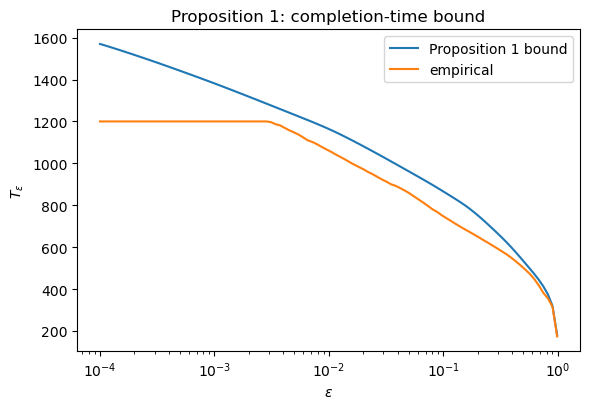

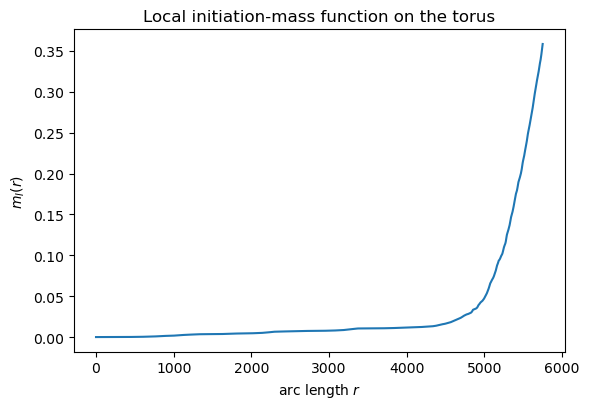

In [117]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# Empirical comparison helper
# ============================================================

def _higher_quantiles(x, q):
    x = np.sort(np.asarray(x, dtype=float), axis=0)
    n = x.shape[0]
    q = np.asarray(q, dtype=float)
    k = np.clip(np.ceil(q * n).astype(int) - 1, 0, n - 1)
    return x[k]


# ============================================================
# Proposition 1 ingredients on the torus
# ============================================================

def _torus_width(sigma, L, vmin):
    """
    w_{T_L}(sigma) = min(2 vmin sigma, L)
    """
    sigma = np.asarray(sigma, dtype=float)
    return np.minimum(2.0 * vmin * sigma, L)


def _torus_local_mass(I, lengths, dx=1.0):
    """
    Discrete approximation of the local initiation-mass function

        m_I(r) = inf_y ∫_{A_r(y)} I(ξ) dξ

    on the torus, assuming I is sampled on a regular grid of spacing dx
    and using bin-aligned starting points.

    Parameters
    ----------
    I : 1D array
        Initiation-rate density sampled on the circle.
    lengths : scalar or 1D array
        Arc lengths r at which to evaluate m_I(r).
    dx : float
        Bin size in physical length units.

    Returns
    -------
    np.ndarray
        m_I(lengths)
    """
    I = np.asarray(I, dtype=float)
    lengths = np.atleast_1d(np.asarray(lengths, dtype=float))

    n = len(I)
    L = n * dx
    idx = np.arange(n)

    mass = np.concatenate([I, I])
    prefix = np.concatenate([[0.0], np.cumsum(mass)])

    out = np.empty_like(lengths, dtype=float)

    for k, r in enumerate(lengths):
        if r <= 0:
            out[k] = 0.0
            continue
        if r >= L:
            out[k] = dx * np.sum(I)
            continue

        u = r / dx
        q = int(np.floor(u))
        frac = u - q

        # full-bin contribution for all starts j = 0,...,n-1
        totals = dx * (prefix[idx + q] - prefix[idx])

        # fractional tail
        if frac > 0:
            totals = totals + frac * dx * I[(idx + q) % n]

        out[k] = np.min(totals)

    return out


def proposition1_torus_curve(frates, vmin=1.4, dx=1.0, rhs_max=None, num_t=4000):
    """
    Build the cumulative function

        F(t) = ∫_0^t m_I(min(2 vmin sigma, L)) d sigma

    needed for Proposition 1 on the torus.

    Parameters
    ----------
    frates : 1D array
        Initiation-rate density profile I(x), assumed time-independent.
    vmin : float
        Lower bound on fork speed.
    dx : float
        Bin size.
    rhs_max : float or None
        Maximum log(1/eps) you want to reach. If None, defaults to log(1/1e-4).
    num_t : int
        Number of time grid points.

    Returns
    -------
    dict with keys:
        I, L, dx, vmin, t, r, mI, F
    """
    I = np.asarray(frates, dtype=float)
    if I.ndim != 1:
        raise ValueError("frates must be a 1D array")
    if np.any(I < 0):
        raise ValueError("frates must be nonnegative")
    if vmin <= 0 or dx <= 0:
        raise ValueError("vmin and dx must be positive")

    L = len(I) * dx

    if rhs_max is None:
        rhs_max = np.log(1.0 / 1e-4)

    # On the torus, once the cone has wrapped fully, m_I(L) is just the total mass.
    mL = dx * np.sum(I)
    if mL <= 0:
        raise ValueError("Total initiation mass must be positive")

    t_wrap = L / (2.0 * vmin)

    # Conservative t_max so that F(t) should exceed rhs_max
    t_max = t_wrap + rhs_max / mL + dx / vmin

    while True:
        t = np.linspace(0.0, t_max, num_t)
        r = _torus_width(t, L, vmin)

        # r is monotone, so evaluate m_I only on unique values
        r_unique, inv = np.unique(r, return_inverse=True)
        m_unique = _torus_local_mass(I, r_unique, dx=dx)
        mI = m_unique[inv]

        # cumulative trapezoid
        dt = np.diff(t)
        F = np.empty_like(t)
        F[0] = 0.0
        F[1:] = np.cumsum(0.5 * (mI[:-1] + mI[1:]) * dt)

        if F[-1] >= rhs_max:
            break

        t_max *= 2.0

    return {
        "I": I,
        "L": L,
        "dx": dx,
        "vmin": float(vmin),
        "t": t,
        "r": r,
        "mI": mI,
        "F": F,
    }


def bound_proposition1(eps, frates, vmin=1.4, dx=1.0, num_t=4000):
    """
    Proposition 1 torus bound for T_eps, under the approximation
    that I(x,tau) = frates(x) is time-independent.

    Returns
    -------
    T_bound : np.ndarray
    aux : dict
        Contains the precomputed curve and ingredients.
    """
    eps = np.asarray(eps, dtype=float)
    if np.any((eps <= 0) | (eps >= 1)):
        raise ValueError("eps must lie strictly in (0, 1)")

    rhs = np.log(1.0 / eps)
    aux = proposition1_torus_curve(
        frates=frates,
        vmin=vmin,
        dx=dx,
        rhs_max=float(np.max(rhs)),
        num_t=num_t,
    )

    # Invert F(t) = log(1/eps)
    T_bound = np.interp(rhs, aux["F"], aux["t"])
    return T_bound, aux


# ============================================================
# Comparison with empirical completion curve
# ============================================================

def compare_proposition1(frates, rep_times_per_sim, fork_speed=1.4, dx=1.0, eps_grid=None, num_t=4000):
    tau = np.asarray(rep_times_per_sim, dtype=float)
    if tau.ndim != 2:
        raise ValueError("rep_times_per_sim must have shape (n_sims, n_pos)")
    if tau.shape[1] != len(frates):
        raise ValueError("rep_times_per_sim.shape[1] must equal len(frates)")

    if eps_grid is None:
        eps_grid = np.geomspace(1e-4, 0.99, 100)
    eps_grid = np.asarray(eps_grid, dtype=float)

    T_theory, aux = bound_proposition1(
        eps=eps_grid,
        frates=frates,
        vmin=fork_speed,
        dx=dx,
        num_t=num_t,
    )

    q = 1.0 - eps_grid
    T_empirical = _higher_quantiles(tau, q).max(axis=1)

    return {
        "eps": eps_grid,
        "T_theory": T_theory,
        "T_empirical": T_empirical,
        "aux": aux,
    }


# ============================================================
# Plots
# ============================================================

def plot_proposition1(res):
    fig, ax = plt.subplots(figsize=(6.0, 4.2))

    ax.plot(res["eps"], res["T_theory"], label="Proposition 1 bound")
    ax.plot(res["eps"], res["T_empirical"], label="empirical")

    ax.set_xscale("log")
    ax.set_xlabel(r"$\varepsilon$")
    ax.set_ylabel(r"$T_\varepsilon$")
    ax.set_title("Proposition 1: completion-time bound")
    ax.legend()
    plt.tight_layout()
    return fig, ax


def plot_proposition1_kernel(res):
    aux = res["aux"]

    fig, ax = plt.subplots(figsize=(6.0, 4.2))
    ax.plot(aux["r"], aux["mI"])
    ax.set_xlabel(r"arc length $r$")
    ax.set_ylabel(r"$m_I(r)$")
    ax.set_title("Local initiation-mass function on the torus")
    plt.tight_layout()
    return fig, ax


# ============================================================
# Example run
# ============================================================

eps_grid = np.geomspace(1e-4, 0.99, 100)

res_prop1 = compare_proposition1(
    frates=frates,
    rep_times_per_sim=rep_times_per_sim,
    fork_speed=1.4,
    dx=1.0,          # change this if your bins are not 1 kb
    eps_grid=eps_grid,
    num_t=4000,
)

fig1, ax1 = plot_proposition1(res_prop1)
fig2, ax2 = plot_proposition1_kernel(res_prop1)

fig1.savefig("figures/proposition1_completion_bound.pdf", bbox_inches="tight")
fig2.savefig("figures/proposition1_local_mass.pdf", bbox_inches="tight")

plt.show()

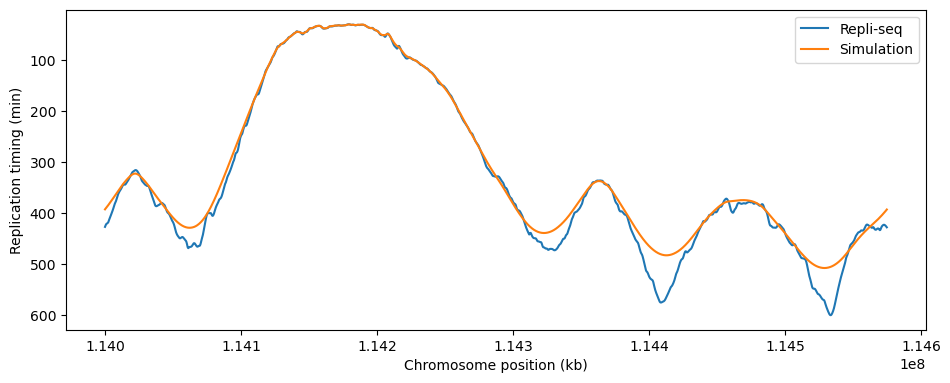

In [118]:
plotf(timedata, timesim, x_array=positions, invyQ=True, xtitle='Chromosome position (kb)', ytitle='Replication timing (min)', labels=['Repli-seq', 'Simulation'], saveQ=True)

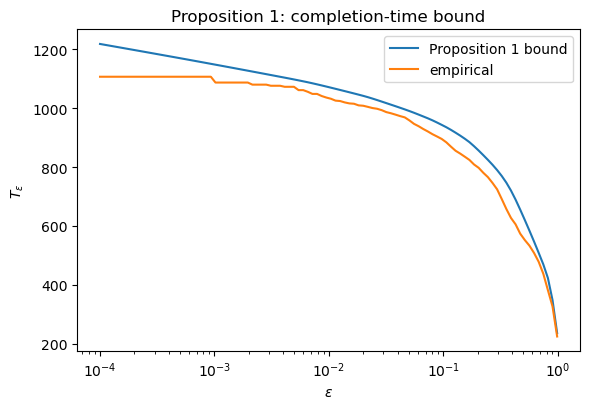

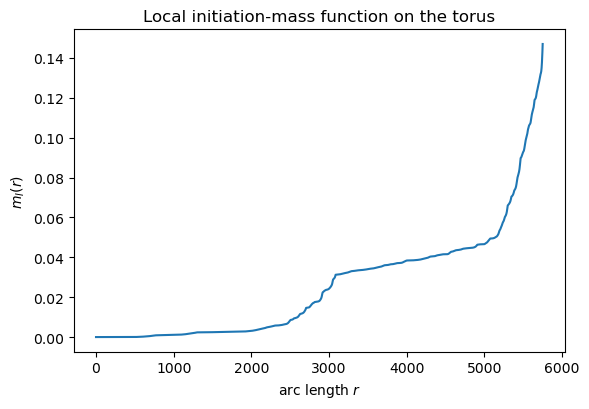

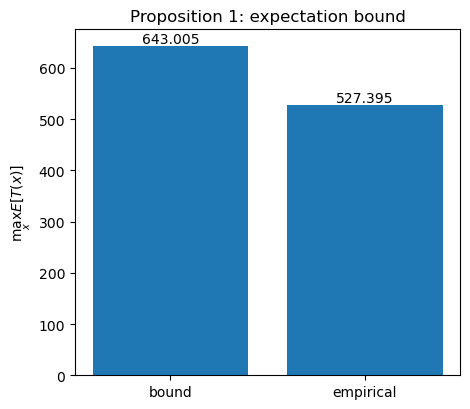

E_theory = 643.0046987316503
E_empirical = 527.3949819653513
